# Stochastic Mechanical-Vulnerability Analysis

## 1. Objective

Our previous structural FEM simulation demonstrated that irregular biofilm
geometries develop nonuniform internal stresses under externally applied
mechanical loading.

However, biofilm morphology is inherently variable. Consequently,
conclusions drawn from a single geometry may not generalize to other
biofilm structures.

We therefore use stochastic modelling to investigate how hypothetical
biofilm thickness regulation affects mechanical vulnerability across
different surface morphologies.

### Paired experimental design

For each randomly generated biofilm:

$$
h_u(x)=h_0+r(x)
$$

where $h_0$ is the mean thickness and $r(x)$ represents random surface
variations.

We construct a hypothetical regulated biofilm:

$$
\boxed{
h_r(x)=\alpha h_u(x)
}
$$

where $0<\alpha\leq1$.

For our initial experiment:

$$
\alpha=0.5
$$

Both geometries share the same underlying surface morphology, allowing
us to investigate the effect of thickness reduction without introducing
an independent random geometry.

### Mechanical loading

To isolate the effect of geometry, we prescribe the same total
horizontal force per unit out-of-plane depth across simulations:

$$
\boxed{
F_x^{\mathrm{applied}}=F_{\mathrm{ref}}
}
$$

Since the exposed surface length varies between biofilms, the
corresponding uniform horizontal traction is:

$$
\boxed{
t_x=\frac{F_{\mathrm{ref}}}{L_s}
}
$$

where $L_s$ is the actual length of the irregular biofilm surface.

This ensures that different geometries experience identical total
horizontal loading.

The prescribed force is illustrative and does not yet represent
CFD-derived fluid forces or bellows-induced deformation.

In [3]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.stochastic_geometry import random_height_profile
from src.structural_fem import solve_biofilm

install jax and jaxlib to use terms_jax.py!
sfepy: WARNING: module /Users/zewei/miniconda3/envs/biofilm-fem/lib/python3.13/site-packages/sfepy/terms/terms_jax.py cannot be imported!
sfepy: reason:
 No module named 'jax'


## 2. Experimental Parameters

We generate 20 independent stochastic biofilm morphologies.

All unregulated biofilms have the same target mean thickness and RMS
height roughness, but differ in the spatial arrangement of their
surface features.

The regulated biofilms are generated by multiplying the corresponding
unregulated height profiles by a constant factor.

### Material properties

We retain the same illustrative material parameters used in our
previous structural FEM model:

$$
E=64\ \mathrm{Pa},\qquad \nu=0.3
$$

The material properties are initially assumed unchanged by regulation.

This allows us to isolate geometric effects, but does not establish
whether gamma-PGA regulation changes biofilm stiffness or cohesion.

### Reference loading

We define the reference force using the total force from our previous
structural FEM simulation:

$$
F_{\mathrm{ref}}=5.252825\times10^{-6}\ \mathrm{N/m}
$$

This force is applied uniformly along each biofilm's exposed surface,
with the traction magnitude adjusted to account for differences in
surface length.

In [5]:
# Geometry
L = 500.0
nx = 501
x = np.linspace(0, L, nx)

# Stochastic parameters
N_SAMPLES = 20
N_FEATURES = 10

MEAN_HEIGHT = 80.0
ROUGHNESS = 15.0
MIN_HEIGHT = 5.0

# Hypothetical regulation
ALPHA = 0.5

# Mechanical properties
E = 64.0
NU = 0.3

# Reference force per unit out-of-plane depth (N/m)
F_REF = 5.252825e-6

# FEM resolution
NY = 60

print("Experimental parameters initialized.")

Experimental parameters initialized.


## 3. Generating Paired Biofilm Morphologies

For each random seed, we generate one unregulated biofilm and construct
a regulated counterpart using:

$$
h_r(x)=0.5h_u(x)
$$

The same underlying morphology is therefore retained within each pair.

This approach reduces variability caused by independently generated
surface features.

However, uniform height scaling also reduces the absolute roughness
and surface slopes. Consequently, the experiment investigates the
combined geometric effects of this specific scaling transformation,
rather than thickness alone.

The transformation is hypothetical and will eventually need to be
replaced or calibrated using experimental measurements.

In [7]:
paired_profiles = {}

for seed in range(N_SAMPLES):

    h_u = random_height_profile(
        x,
        mean_height=MEAN_HEIGHT,
        roughness=ROUGHNESS,
        n_features=N_FEATURES,
        min_height=MIN_HEIGHT,
        rng=np.random.default_rng(seed)
    )

    h_r = ALPHA * h_u

    paired_profiles[seed] = {
        "unregulated": h_u,
        "regulated": h_r
    }

print(f"Generated {len(paired_profiles)} paired morphologies.")

Generated 20 paired morphologies.


## 4. Normalizing External Mechanical Loading

The total horizontal force exerted by a uniform traction on an
irregular surface is:

$$
F_x=t_x L_s
$$

where:

$$
L_s=\int_0^L
\sqrt{1+\left(\frac{dh}{dx}\right)^2}\,dx
$$

To ensure that all biofilms experience the same total horizontal force,
we calculate:

$$
\boxed{
t_x=\frac{F_{\mathrm{ref}}}{L_s}
}
$$

This removes differences in total applied force caused by variations
in exposed surface length.

However, it does not reproduce actual fluid mechanics. In reality,
pressure and shear stresses depend on local surface orientation,
fluid velocity, and surrounding geometry.

In [8]:
UM = 1e-6

def surface_length(x, h):
    """
    Calculate piecewise-linear surface length.

    x, h: micrometres.
    Returns: metres.
    """

    dx = np.diff(x)
    dh = np.diff(h)

    segment_lengths = np.sqrt(dx**2 + dh**2)

    return segment_lengths.sum() * UM


def normalized_traction(x, h, reference_force):
    """
    Calculate uniform horizontal traction (Pa)
    required to produce the specified total force (N/m).
    """

    L_surface = surface_length(x, h)

    return reference_force / L_surface

In [9]:
for condition, h_sample in paired_profiles[0].items():

    L_surface = surface_length(x, h_sample)

    tx = normalized_traction(x, h_sample, F_REF)

    print(
        f"{condition:12s} | "
        f"Surface length = {L_surface / UM:.2f} μm | "
        f"Traction = {tx:.6f} Pa | "
        f"Total force = {tx * L_surface:.6e} N/m"
    )

unregulated  | Surface length = 525.28 μm | Traction = 0.010000 Pa | Total force = 5.252825e-06 N/m
regulated    | Surface length = 506.77 μm | Traction = 0.010365 Pa | Total force = 5.252825e-06 N/m


## 5. First Paired FEM Comparison

We first solve the structural elasticity problem for one unregulated
biofilm and its corresponding regulated geometry.

Both simulations use identical:

- Material properties.
- Total horizontal force.
- Plane-strain formulation.
- Fixed-substrate boundary conditions.

The only difference is the prescribed geometric transformation:

$$
h_r(x)=0.5h_u(x)
$$

We compare the interior maximum von Mises stress and maximum
displacement.

The interior maximum excludes regions within 5 μm of the two
fixed-base corners, consistent with our previous convergence study.

These quantities describe mechanical response and do not directly
predict fracture or sloughing.

In [10]:
seed = 0

first_pair_results = {}

for condition, h_sample in paired_profiles[seed].items():

    tx = normalized_traction(x, h_sample, F_REF)

    result = solve_biofilm(
        x=x,
        h=h_sample,
        ny=NY,
        E=E,
        nu=NU,
        traction_x=tx
    )

    first_pair_results[condition] = result

    print(
        f"{condition:12s} | "
        f"Interior stress = {result['interior_peak']:.6f} Pa | "
        f"Max displacement = {result['max_displacement_um']:.6f} μm"
    )

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (60120, 60120)
sfepy: assembling matrix graph...
sfepy: ...done in 0.02 s
sfepy: matrix structural nonzeros: 832712 (2.30e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     biofilm
sfepy:     traction
sfepy: ...done in 0.01 s
sfepy: nls: iter: 0, residual: 2.356466e-07 (rel: 1.000000e+00)
sfepy:   residual:    0.02 [s]
sfepy:     matrix:    0.01 [s]
sfepy:      solve:    0.21 [s]
sfepy: nls: iter: 1, residual: 3.185742e-19 (rel: 1.351915e-12)
sfepy: solved in 1 steps in 0.27 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
unregulated  | Interior stress = 0.03965

## 6. Stochastic FEM Ensemble

The first paired simulation suggests that hypothetical thickness reduction
decreases interior maximum stress under identical total mechanical loading.

However, this result is based on a single randomly generated morphology.

We therefore repeat the experiment across 20 independent stochastic
biofilm geometries.

For each seed, we generate an unregulated biofilm and its corresponding
regulated geometry:

$$
h_r(x)=0.5h_u(x)
$$

Both geometries experience the same total horizontal force:

$$
F_x=5.252825\times10^{-6}\ \mathrm{N/m}
$$

We calculate the interior maximum von Mises stress and maximum
displacement for each simulation.

The paired design allows us to investigate whether the predicted
mechanical response changes consistently across different morphologies.

These comparisons represent hypothetical geometric regulation, not
experimental validation of our optogenetic system.

In [11]:
ensemble_results = []

for seed, pair in paired_profiles.items():

    for condition, h_sample in pair.items():

        # Normalize traction to maintain identical total force
        tx = normalized_traction(x, h_sample, F_REF)

        # Solve structural FEM
        r = solve_biofilm(
            x=x,
            h=h_sample,
            ny=NY,
            E=E,
            nu=NU,
            traction_x=tx
        )

        ensemble_results.append({
            "seed": seed,
            "condition": condition,
            "mean_height": np.trapezoid(h_sample, x) / L,
            "interior_peak": r["interior_peak"],
            "global_peak": r["global_peak"],
            "max_displacement": r["max_displacement_um"],
            "max_strain": r["max_principal_strain"]
        })

df = pd.DataFrame(ensemble_results)

print(f"Completed {len(df)} FEM simulations.")
print(df.head())

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (60120, 60120)
sfepy: assembling matrix graph...
sfepy: ...done in 0.03 s
sfepy: matrix structural nonzeros: 832712 (2.30e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     traction
sfepy:     biofilm
sfepy: ...done in 0.01 s
sfepy: nls: iter: 0, residual: 2.356466e-07 (rel: 1.000000e+00)
sfepy:   residual:    0.02 [s]
sfepy:     matrix:    0.01 [s]
sfepy:      solve:    0.21 [s]
sfepy: nls: iter: 1, residual: 3.185742e-19 (rel: 1.351915e-12)
sfepy: solved in 1 steps in 0.26 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: updating variables...
sfepy: ...d

In [12]:
# Arrange results so each seed has both conditions
comparison = df.pivot(
    index="seed",
    columns="condition",
    values=["interior_peak", "max_displacement"]
)

# Percentage change in interior stress
stress_change = (
    comparison["interior_peak"]["regulated"]
    / comparison["interior_peak"]["unregulated"]
    - 1
) * 100

# Percentage change in displacement
displacement_change = (
    comparison["max_displacement"]["regulated"]
    / comparison["max_displacement"]["unregulated"]
    - 1
) * 100

print("=== Stochastic Comparison ===")

print(f"Mean stress change: {stress_change.mean():.2f}%")
print(f"Median stress change: {stress_change.median():.2f}%")

print(
    "Pairs with reduced interior stress:",
    (stress_change < 0).sum(),
    "/",
    N_SAMPLES
)

print(f"\nMean displacement change: {displacement_change.mean():.2f}%")
print(f"Median displacement change: {displacement_change.median():.2f}%")

=== Stochastic Comparison ===
Mean stress change: -23.96%
Median stress change: -24.07%
Pairs with reduced interior stress: 20 / 20

Mean displacement change: -55.53%
Median displacement change: -55.64%


## 7. Evaluating Mechanical Vulnerability

Although reducing biofilm thickness decreases the calculated interior
maximum stress, this does not necessarily imply a lower likelihood
of mechanical failure.

Mechanical vulnerability depends on both the internal stress and
the biofilm's resistance to failure.

We introduce an illustrative effective strength threshold,
$\sigma_t$, and classify elements as potentially overstressed when:

$$
\sigma_e > \sigma_t
$$

The area-weighted overstress fraction is:

$$
\boxed{
f_{\mathrm{overstress}} =
\frac{
\sum_i A_i \mathbb{1}(\sigma_{e,i}>\sigma_t)
}{
\sum_i A_i
}
}
$$

This measures the fraction of the biofilm's cross-sectional area
experiencing equivalent stress above the assumed threshold.

It does not represent the fraction of biofilm that has detached,
nor does it directly predict downstream filter clogging.

We will investigate how this metric changes under different
hypothetical material-strength scenarios.

In [13]:
def overstress_fraction(sigma_e, areas, sigma_t):
    """
    Calculate area-weighted fraction exceeding a stress threshold.
    """
    return areas[sigma_e > sigma_t].sum() / areas.sum()

# Illustrative effective strength thresholds (Pa)
strengths = [0.01, 0.02, 0.03, 0.05, 0.10]

for sigma_t in strengths:

    print(f"\nStrength threshold: {sigma_t:.3f} Pa")

    for condition, r in first_pair_results.items():

        fraction = overstress_fraction(
            r["sigma_e"],
            r["areas"],
            sigma_t
        )

        print(
            f"  {condition:12s}: "
            f"{fraction:.2%} overstressed"
        )


Strength threshold: 0.010 Pa
  unregulated : 99.58% overstressed
  regulated   : 99.70% overstressed

Strength threshold: 0.020 Pa
  unregulated : 24.59% overstressed
  regulated   : 17.52% overstressed

Strength threshold: 0.030 Pa
  unregulated : 1.02% overstressed
  regulated   : 0.14% overstressed

Strength threshold: 0.050 Pa
  unregulated : 0.01% overstressed
  regulated   : 0.00% overstressed

Strength threshold: 0.100 Pa
  unregulated : 0.00% overstressed
  regulated   : 0.00% overstressed


## 8. Stochastic Mechanical-Vulnerability Analysis

The previous analysis demonstrated that hypothetical biofilm thinning
can reduce the area experiencing elevated equivalent stress.

However, the magnitude of this reduction depends on the assumed
mechanical-strength threshold.

To investigate whether this relationship is consistent across
different morphologies, we evaluate the area-weighted overstress
fraction for all 20 paired biofilms.

For each biofilm geometry, the overstress fraction is:

$$
f_{\mathrm{overstress}}(\sigma_t)=
\frac{
\sum_i A_i\mathbb{1}(\sigma_{e,i}>\sigma_t)
}{
\sum_i A_i
}
$$

We vary $\sigma_t$ while keeping the calculated stress field
unchanged.

This allows us to investigate sensitivity to assumed material
strength without repeatedly solving the elasticity equations.

The resulting fractions describe predicted threshold exceedance,
not actual fracture or detached biomass.

In [14]:
# Store complete FEM results
ensemble_fields = {}

for seed, pair in paired_profiles.items():

    ensemble_fields[seed] = {}

    for condition, h_sample in pair.items():

        tx = normalized_traction(x, h_sample, F_REF)

        r = solve_biofilm(
            x=x,
            h=h_sample,
            ny=NY,
            E=E,
            nu=NU,
            traction_x=tx
        )

        ensemble_fields[seed][condition] = {
            "sigma_e": r["sigma_e"],
            "areas": r["areas"]
        }

print("Stored stress fields for all 40 simulations.")

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (60120, 60120)
sfepy: assembling matrix graph...
sfepy: ...done in 0.03 s
sfepy: matrix structural nonzeros: 832712 (2.30e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     traction
sfepy:     biofilm
sfepy: ...done in 0.01 s
sfepy: nls: iter: 0, residual: 2.356466e-07 (rel: 1.000000e+00)
sfepy:   residual:    0.02 [s]
sfepy:     matrix:    0.01 [s]
sfepy:      solve:    0.21 [s]
sfepy: nls: iter: 1, residual: 3.185742e-19 (rel: 1.351915e-12)
sfepy: solved in 1 steps in 0.26 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: updating variables...
sfepy: ...d

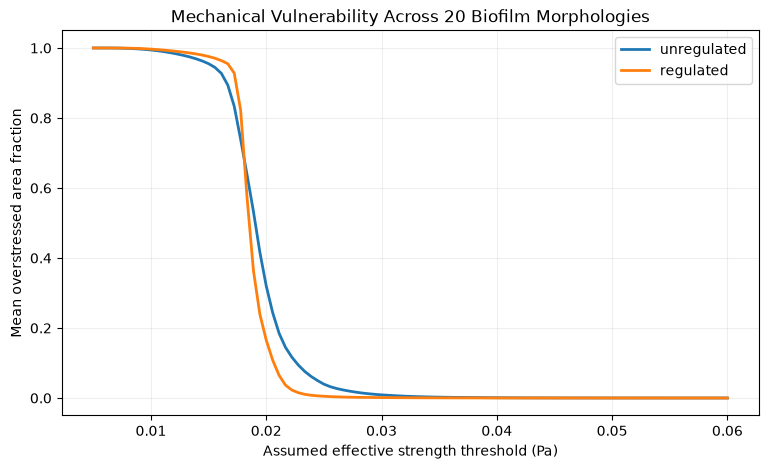

In [16]:
strengths = np.linspace(0.005, 0.06, 100)

vulnerability_results = []

for seed, pair in ensemble_fields.items():

    for condition, r in pair.items():

        for sigma_t in strengths:

            fraction = overstress_fraction(
                r["sigma_e"],
                r["areas"],
                sigma_t
            )

            vulnerability_results.append({
                "seed": seed,
                "condition": condition,
                "strength": sigma_t,
                "overstress_fraction": fraction
            })

vulnerability_df = pd.DataFrame(vulnerability_results)

fig, ax = plt.subplots(figsize=(9, 5))

for condition in ["unregulated", "regulated"]:

    subset = vulnerability_df[
        vulnerability_df["condition"] == condition
    ]

    mean_fraction = subset.groupby(
        "strength"
    )["overstress_fraction"].mean()

    ax.plot(
        mean_fraction.index,
        mean_fraction.values,
        label=condition,
        linewidth=2
    )

ax.set_xlabel("Assumed effective strength threshold (Pa)")
ax.set_ylabel("Mean overstressed area fraction")
ax.set_title("Mechanical Vulnerability Across 20 Biofilm Morphologies")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

## 9. Investigating the Strength–Thickness Trade-off

Our previous stochastic FEM analysis demonstrated that hypothetical
50% thickness reduction decreases the interior maximum stress across
all 20 sampled biofilm morphologies.

However, gamma-PGA regulation may also alter the mechanical properties
of the biofilm matrix.

We therefore investigate whether the geometric benefits of thinning
persist when the regulated biofilm experiences a reduction in its
effective mechanical strength.

### Strength-retention factor

We define:

$$
\boxed{
\beta=\frac{\sigma_{t,r}}{\sigma_{t,u}}
}
$$

where:

- $\sigma_{t,u}$: Assumed effective strength of the unregulated biofilm.
- $\sigma_{t,r}$: Assumed effective strength of the regulated biofilm.
- $\beta$: Fraction of original strength retained after regulation.

For example, $\beta=0.8$ represents a 20% reduction in strength.

### Mechanical-vulnerability comparison

The unregulated biofilm is evaluated using:

$$
f_u(\sigma_{t,u})
$$

The regulated biofilm is evaluated using:

$$
f_r(\beta\sigma_{t,u})
$$

We define the change in overstressed-area fraction as:

$$
\boxed{
\Delta f=f_r-f_u
}
$$

A negative value indicates that regulation reduces the fraction
of biofilm exceeding its respective assumed strength threshold.

A positive value indicates increased threshold exceedance.

This is a sensitivity analysis, not a validated prediction of
biofilm fracture or detachment.

In [18]:
# Strength-retention factors
betas = np.linspace(0.2, 1.2, 101)

# Assumed unregulated strength thresholds (Pa)
strengths_u = np.linspace(0.005, 0.06, 111)

# Store mean change in overstressed-area fraction
delta_f = np.zeros((len(betas), len(strengths_u)))

for i, beta in enumerate(betas):

    for j, sigma_t_u in enumerate(strengths_u):

        differences = []

        for seed, pair in ensemble_fields.items():

            u = pair["unregulated"]
            r = pair["regulated"]

            # Unregulated vulnerability
            f_u = overstress_fraction(
                u["sigma_e"],
                u["areas"],
                sigma_t_u
            )

            # Regulated vulnerability
            sigma_t_r = beta * sigma_t_u

            f_r = overstress_fraction(
                r["sigma_e"],
                r["areas"],
                sigma_t_r
            )

            differences.append(f_r - f_u)

        # Average across 20 paired geometries
        delta_f[i, j] = np.mean(differences)

print("Strength-retention sensitivity analysis completed.")

Strength-retention sensitivity analysis completed.


## 10. Visualizing the Strength–Vulnerability Trade-off

We visualize the mean difference in overstressed-area fraction:

$$
\Delta f=
\overline{f_r-f_u}
$$

The horizontal axis represents the assumed effective strength
of the unregulated biofilm.

The vertical axis represents the strength-retention factor $\beta$.

The colour indicates whether hypothetical regulation increases
or decreases mechanical vulnerability.

- $\Delta f<0$: Regulation reduces overstressed area.
- $\Delta f>0$: Regulation increases overstressed area.
- $\Delta f=0$: Both scenarios have equal overstressed fractions.

The zero contour separates parameter combinations where the
regulated biofilm has lower or higher mean threshold exceedance.

This boundary is specific to the assumed geometry transformation,
loading conditions, and equivalent-stress criterion.

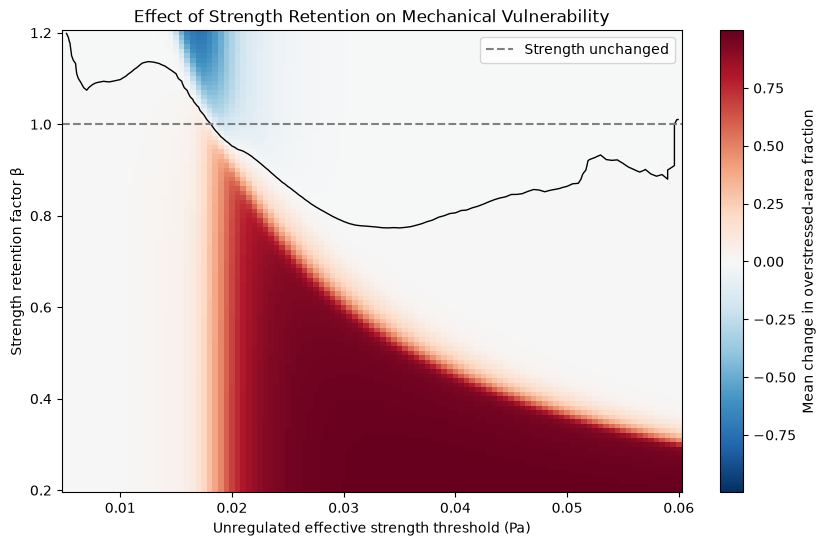

In [20]:
from matplotlib.colors import TwoSlopeNorm

fig, ax = plt.subplots(figsize=(10, 6))

# Symmetric colour scale around zero
limit = np.max(np.abs(delta_f))

norm = TwoSlopeNorm(
    vmin=-limit,
    vcenter=0,
    vmax=limit
)

mesh_plot = ax.pcolormesh(
    strengths_u,
    betas,
    delta_f,
    shading="auto",
    cmap="RdBu_r",
    norm=norm
)

# Boundary between improvement and worsening
ax.contour(
    strengths_u,
    betas,
    delta_f,
    levels=[0],
    colors="black",
    linewidths=1
)

# Reference: no change in strength
ax.axhline(
    1.0,
    color="gray",
    linestyle="--",
    label="Strength unchanged"
)

fig.colorbar(
    mesh_plot,
    ax=ax,
    label="Mean change in overstressed-area fraction"
)

ax.set_xlabel("Unregulated effective strength threshold (Pa)")
ax.set_ylabel("Strength retention factor β")

ax.set_title(
    "Effect of Strength Retention on Mechanical Vulnerability"
)

ax.legend()
plt.show()